In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Loading the cleaned dataset
data_path = Path("../data/processed/DataCoSupplyChain_cleaned.csv")

df = pd.read_csv(data_path)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

display(df.head())

Shape: (180519, 51)
Missing values: 11


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,shipping_delay_days
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,-1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,0
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class,-1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class,-2


In [2]:
# Defining the prediction target
target = "Late_delivery_risk"

# columns that could leak information about the outcome
leakage_columns = [
    "Delivery Status",
    "Days for shipping (real)",
    "shipping date (DateOrders)",
    "shipping_delay_days"
]

# checking the target distribution
print("Target:", target)
print("\nTarget Distribution")
print(df[target].value_counts())

print("\nTarget Percentages")
print(
    (df[target].value_counts(normalize=True) * 100).round(2)
)

print("\nPotential Leakage columns:")
for col in leakage_columns:
    print(f"- {col}: {'Present' if col in df.columns else 'Not Found'}")

Target: Late_delivery_risk

Target Distribution
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Target Percentages
Late_delivery_risk
1    54.83
0    45.17
Name: proportion, dtype: float64

Potential Leakage columns:
- Delivery Status: Present
- Days for shipping (real): Present
- shipping date (DateOrders): Present
- shipping_delay_days: Present


In [3]:
# Inspecting all available columns
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Total columns: 51
1. Type
2. Days for shipping (real)
3. Days for shipment (scheduled)
4. Benefit per order
5. Sales per customer
6. Delivery Status
7. Late_delivery_risk
8. Category Id
9. Category Name
10. Customer City
11. Customer Country
12. Customer Email
13. Customer Fname
14. Customer Id
15. Customer Lname
16. Customer Segment
17. Customer State
18. Customer Street
19. Customer Zipcode
20. Department Id
21. Department Name
22. Latitude
23. Longitude
24. Market
25. Order City
26. Order Country
27. Order Customer Id
28. order date (DateOrders)
29. Order Id
30. Order Item Cardprod Id
31. Order Item Discount
32. Order Item Discount Rate
33. Order Item Id
34. Order Item Product Price
35. Order Item Profit Ratio
36. Order Item Quantity
37. Sales
38. Order Item Total
39. Order Profit Per Order
40. Order Region
41. Order State
42. Order Status
43. Product Card Id
44. Product Category Id
45. Product Image
46. Product Name
47. Product Price
48. Product Status
49. shipping date (DateOrders

In [4]:
selected_features = [
    "Type",
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Category Name",
    "Department Name",
    "Product Price",
    "Order Item Product Price",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Customer Segment",
    "Market",
    "Order Region",
    "Order Country"
]

#creating a separate modelling datset
model_df = df[selected_features + [target]].copy()

#extracting useful timing features from the order date
order_dates = pd.to_datetime(
    df["order date (DateOrders)"], errors="coerce"
)

model_df["order_month"] = order_dates.dt.month
model_df["order_day_of_week"] = order_dates.dt.day_of_week

# Inspect the result
print("Modelling dataset shape:", model_df.shape)

print("\nFirst five rows:")
display(model_df.head())

print("\nData types:")
print(model_df.dtypes)

print("\nMissing values per column:")
print(model_df.isnull().sum())

Modelling dataset shape: (180519, 17)

First five rows:


,Type,Days for shipment (scheduled),Shipping Mode,Category Name,Department Name,Product Price,Order Item Product Price,Order Item Quantity,Order Item Discount,Order Item Discount Rate,Customer Segment,Market,Order Region,Order Country,Late_delivery_risk,order_month,order_day_of_week
0,DEBIT,4,Standard Class,Sporting Goods,Fitness,327.75,327.75,1,13.110000,0.04,Consumer,Pacific Asia,Southeast Asia,Indonesia,0,1,2
1,TRANSFER,4,Standard Class,Sporting Goods,Fitness,327.75,327.75,1,16.389999,0.05,Consumer,Pacific Asia,South Asia,India,1,1,5
2,CASH,4,Standard Class,Sporting Goods,Fitness,327.75,327.75,1,18.030001,0.06,Consumer,Pacific Asia,South Asia,India,0,1,5
3,DEBIT,4,Standard Class,Sporting Goods,Fitness,327.75,327.75,1,22.940001,0.07,Home Office,Pacific Asia,Oceania,Australia,0,1,5
4,PAYMENT,4,Standard Class,Sporting Goods,Fitness,327.75,327.75,1,29.500000,0.09,Corporate,Pacific Asia,Oceania,Australia,0,1,5



Data types:
Type                                 str
Days for shipment (scheduled)      int64
Shipping Mode                        str
Category Name                        str
Department Name                      str
Product Price                    float64
Order Item Product Price         float64
Order Item Quantity                int64
Order Item Discount              float64
Order Item Discount Rate         float64
Customer Segment                     str
Market                               str
Order Region                         str
Order Country                        str
Late_delivery_risk                 int64
order_month                        int32
order_day_of_week                  int32
dtype: object

Missing values per column:
Type                             0
Days for shipment (scheduled)    0
Shipping Mode                    0
Category Name                    0
Department Name                  0
Product Price                    0
Order Item Product Price         0
Ord

In [5]:
# Checking the data type of each column
print("DATA TYPES")
print(model_df.dtypes)

# Count missing values in each column
print("\nMISSING VALUES")
print(model_df.isnull().sum())

# Check for duplicate rows
print("\nDUPLICATE ROWS")
print(model_df.duplicated().sum())

# Separate input features and target
X = model_df.drop(columns=[target])
y = model_df[target]

print("\nInput features shape:", X.shape)
print("Target shape:", y.shape)

DATA TYPES
Type                                 str
Days for shipment (scheduled)      int64
Shipping Mode                        str
Category Name                        str
Department Name                      str
Product Price                    float64
Order Item Product Price         float64
Order Item Quantity                int64
Order Item Discount              float64
Order Item Discount Rate         float64
Customer Segment                     str
Market                               str
Order Region                         str
Order Country                        str
Late_delivery_risk                 int64
order_month                        int32
order_day_of_week                  int32
dtype: object

MISSING VALUES
Type                             0
Days for shipment (scheduled)    0
Shipping Mode                    0
Category Name                    0
Department Name                  0
Product Price                    0
Order Item Product Price         0
Order Item Quanti

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# identifying categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object", "str", "category" , "string"]
).columns.to_list()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

# building the preprocessing step
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

Categorical features: ['Type', 'Shipping Mode', 'Category Name', 'Department Name', 'Customer Segment', 'Market', 'Order Region', 'Order Country']

Numerical features: ['Days for shipment (scheduled)', 'Product Price', 'Order Item Product Price', 'Order Item Quantity', 'Order Item Discount', 'Order Item Discount Rate', 'order_month', 'order_day_of_week']


In [8]:
# combining input features and target for splitting

X = model_df.drop(columns=[target])
Y = model_df[target]

# sorting order dates to establish a chronological cutoff
sorted_dates = order_dates.dropna().sort_values()

# using approximately the earliest 80% of dates for training
cutoff_index = int(len(sorted_dates) * 0.80)
cutoff_date = sorted_dates.iloc[cutoff_index]

# Keeping all orders on or before the cutoff in training
train_mask = order_dates <= cutoff_date
test_mask = order_dates > cutoff_date

# Create training and testing sets
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Display split information
print("Cutoff date:", cutoff_date)

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nTraining date range:")
print(order_dates.loc[train_mask].min(), "to",
      order_dates.loc[train_mask].max())

print("\nTesting date range:")
print(order_dates.loc[test_mask].min(), "to",
      order_dates.loc[test_mask].max())

Cutoff date: 2017-04-22 15:17:00

Training features: (144416, 16)
Testing features: (36103, 16)

Training target distribution:
Late_delivery_risk
1    54.87
0    45.13
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    54.65
0    45.35
Name: proportion, dtype: float64

Training date range:
2015-01-01 00:00:00 to 2017-04-22 15:17:00

Testing date range:
2017-04-22 15:38:00 to 2018-01-31 23:38:00


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,confusion_matrix
)

In [15]:
from sklearn.preprocessing import StandardScaler

# preprocessing: encode categories and scale numeric features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# building Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

In [17]:
# Train the updated model
logistic_model.fit(X_train, y_train)

# Generate test predictions and probabilities
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]
print("Number of test predictions:", len(y_pred))

Number of test predictions: 36103


In [18]:
# calculating evaluation metrics
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred, zero_division=0)
recall = recall_score(y_test,y_pred, zero_division=0)
f1 = f1_score(y_test,y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test,y_prob)

# displaying
print("Logistic Regression Test Results")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Risk (0)", "Risk (1)"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Test Results
Accuracy : 0.6904
Precision: 0.8369
Recall   : 0.5386
F1-score : 0.6554
ROC-AUC  : 0.7370

Classification Report:
              precision    recall  f1-score   support

 No Risk (0)       0.61      0.87      0.72     16371
    Risk (1)       0.84      0.54      0.66     19732

    accuracy                           0.69     36103
   macro avg       0.72      0.71      0.69     36103
weighted avg       0.73      0.69      0.68     36103


Confusion Matrix:
[[14299  2072]
 [ 9104 10628]]


In [19]:
# comparing with random forest

from sklearn.ensemble import RandomForestClassifier

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Creating Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [21]:
# Training Random Forest on the training data

random_forest_model.fit(X_train, y_train)

# Generating predictions on the test data
rf_y_pred = random_forest_model.predict(X_test)

# Generating probabilities for the positive class
rf_y_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Number of test predictions:", len(rf_y_pred))

Number of test predictions: 36103


In [22]:
# evaluating model

rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_y_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_y_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)

print("RANDOM FOREST - TEST RESULTS")
print("-" * 40)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_y_pred,
    target_names=["No Risk (0)", "Risk (1)"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_y_pred))

RANDOM FOREST - TEST RESULTS
----------------------------------------
Accuracy : 0.6900
Precision: 0.8168
Recall   : 0.5580
F1-score : 0.6630
ROC-AUC  : 0.7369

Classification Report:
              precision    recall  f1-score   support

 No Risk (0)       0.61      0.85      0.71     16371
    Risk (1)       0.82      0.56      0.66     19732

    accuracy                           0.69     36103
   macro avg       0.72      0.70      0.69     36103
weighted avg       0.73      0.69      0.69     36103


Confusion Matrix:
[[13902  2469]
 [ 8722 11010]]


In [23]:
# Comparing Logistic Regression and Random Forest

comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1-score": [f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
})

comparison_df = comparison_df.set_index("Model").round(4)

display(comparison_df)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.6904,0.8369,0.5386,0.6554,0.7370
Random Forest,0.6900,0.8168,0.5580,0.6630,0.7369


In [24]:
from pathlib import Path

# Creating a comparison table
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1-score": [f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
}).round(4)

# Creating the reports directory if it doesn't exist
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Saving model comparison results
comparison_path = reports_dir / "model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Model comparison saved to:", comparison_path)
display(comparison_df)

Model comparison saved to: ..\reports\model_comparison.csv


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6904,0.8369,0.5386,0.6554,0.7370
1,Random Forest,0.6900,0.8168,0.5580,0.6630,0.7369


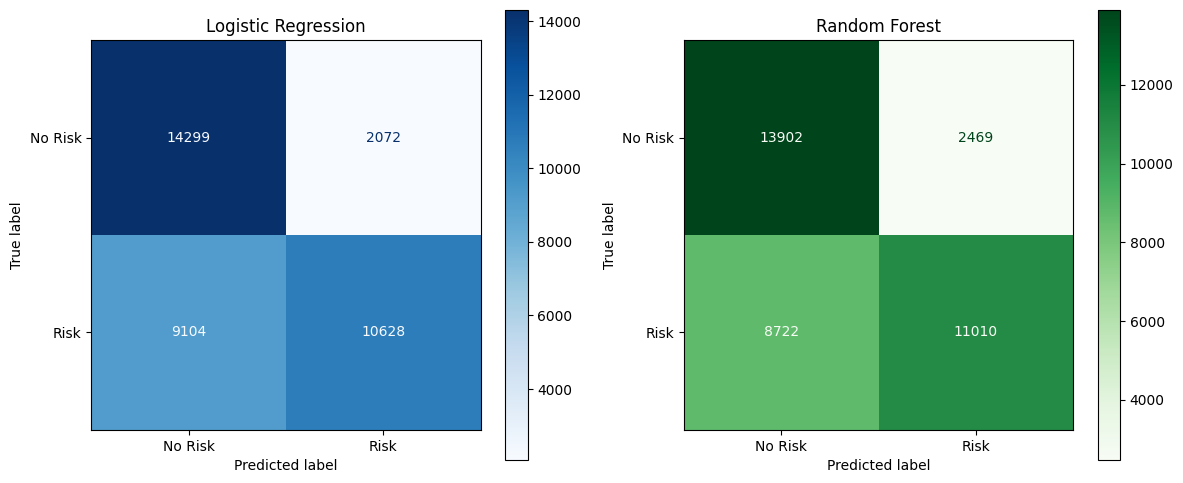

Confusion matrices saved successfully


In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Creating a folder for evaluation plots
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Ploting both models side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Risk", "Risk"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_y_pred,
    display_labels=["No Risk", "Risk"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest")

plt.tight_layout()

# Saving the figure
plt.savefig(
    figures_dir / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully")

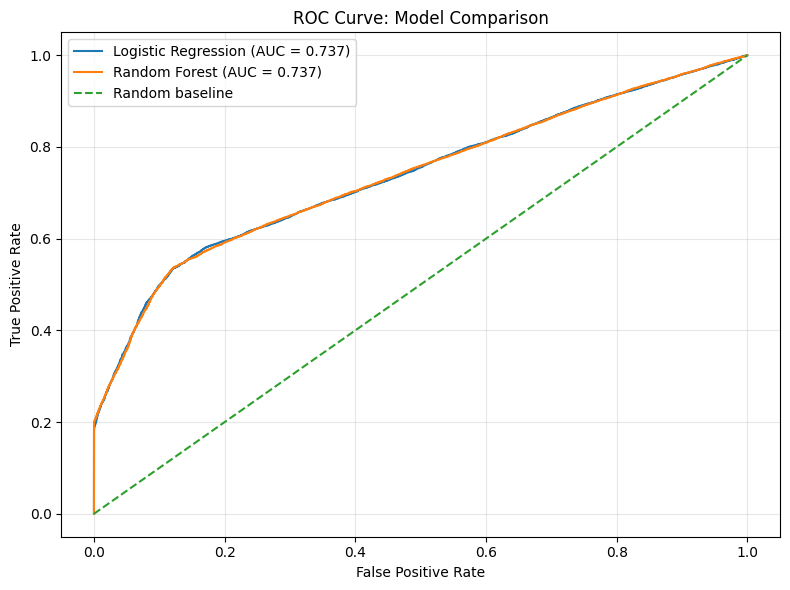

Logistic Regression ROC-AUC: 0.7370
Random Forest ROC-AUC: 0.7369
ROC curve saved successfully


In [27]:
from sklearn.metrics import roc_curve

# Creating output directory
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Calculating ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, y_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_y_prob)

# Calculating AUC
lr_auc = roc_auc_score(y_test, y_prob)
rf_auc = roc_auc_score(y_test, rf_y_prob)

# Plotting curves
plt.figure(figsize=(8, 6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)
plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Saving figure
plt.savefig(
    figures_dir / "roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Logistic Regression ROC-AUC: {lr_auc:.4f}")
print(f"Random Forest ROC-AUC: {rf_auc:.4f}")
print("ROC curve saved successfully")

In [28]:
# Evaluating both models

evaluation_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_y_pred),
        "Precision": precision_score(y_test, rf_y_pred),
        "Recall": recall_score(y_test, rf_y_pred),
        "F1-score": f1_score(y_test, rf_y_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_y_prob)
    }
]).round(4)

# Saving evaluation results
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

evaluation_path = reports_dir / "model_evaluation_results.csv"
evaluation_results.to_csv(evaluation_path, index=False)

display(evaluation_results)
print(f"Evaluation results saved to: {evaluation_path}")

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6904,0.8369,0.5386,0.6554,0.7370
1,Random Forest,0.6900,0.8168,0.5580,0.6630,0.7369


Evaluation results saved to: ..\reports\model_evaluation_results.csv
